<a href="https://colab.research.google.com/github/hcarpenter30/IS4487_my_portfolio/blob/main/carpenter_henry_assignment_06_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv('/content/listings.csv.gz')

## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

                              Missing Count  Missing Percentage
neighborhood_overview                  4939          100.000000
host_since                             4939          100.000000
host_response_time                     4939          100.000000
host_thumbnail_url                     4939          100.000000
host_acceptance_rate                   4939          100.000000
host_response_rate                     4939          100.000000
host_verifications                     4939          100.000000
neighbourhood                          4939          100.000000
host_total_listings_count              4939          100.000000
host_neighbourhood                     4939          100.000000
calendar_updated                       4939          100.000000
instant_bookable                       4939          100.000000
neighbourhood_group_cleansed           4939          100.000000
host_about                             1945           39.380441
license                                1

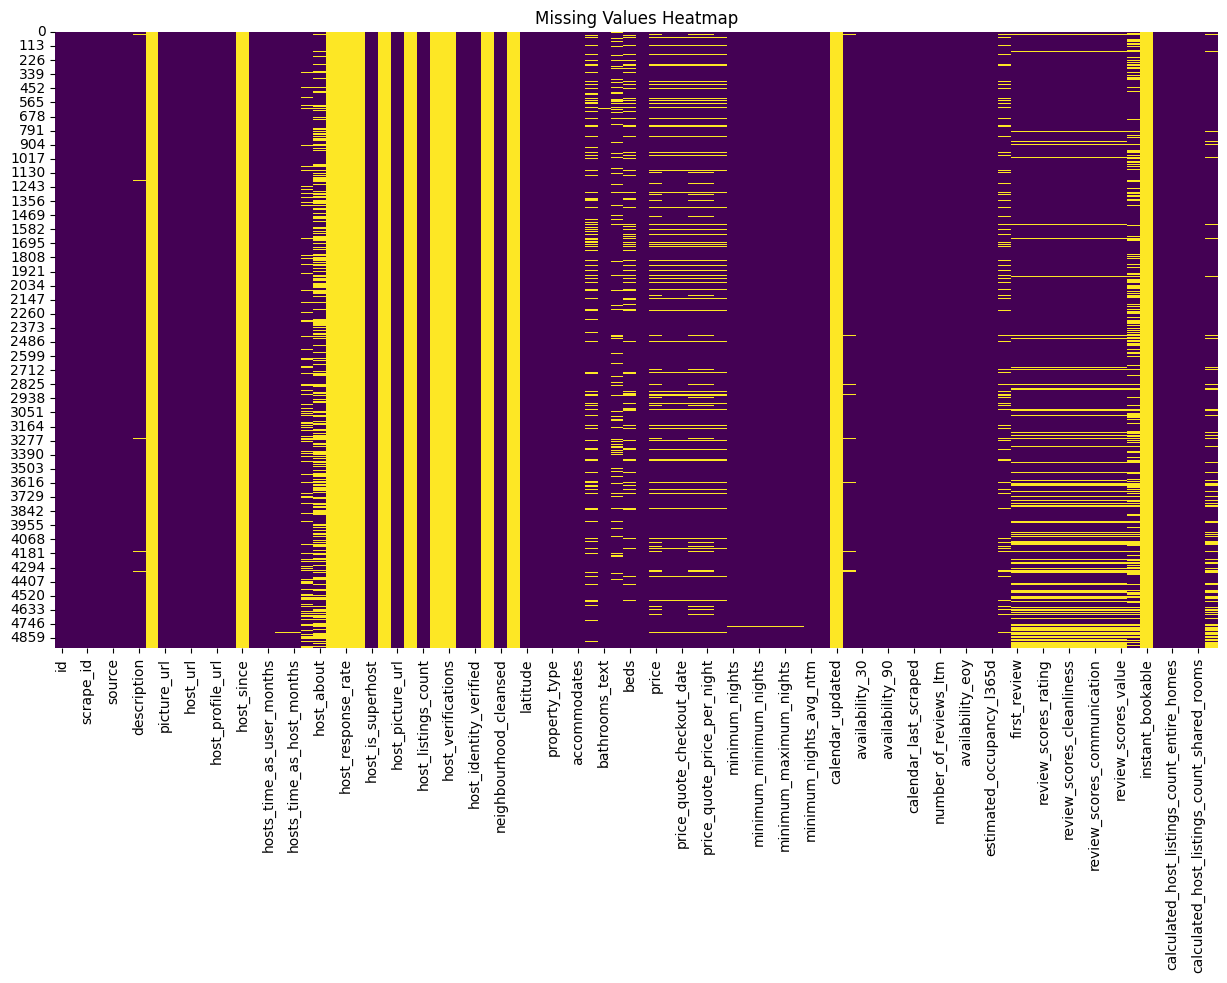

In [10]:
missing_values = df.isnull().sum()
missing_values_percent = (df.isnull().sum() / len(df)) * 100

missing_info = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_values_percent
}).sort_values(by='Missing Count', ascending=False)

print(missing_info[missing_info['Missing Count'] > 0])

# Visualize missing values (e.g., using a heatmap)
plt.figure(figsize=(15, 8))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

/tmp/ipykernel_1928/758463432.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_data_barplot.index, y='Missing Percentage', data=missing_data_barplot, palette='viridis')


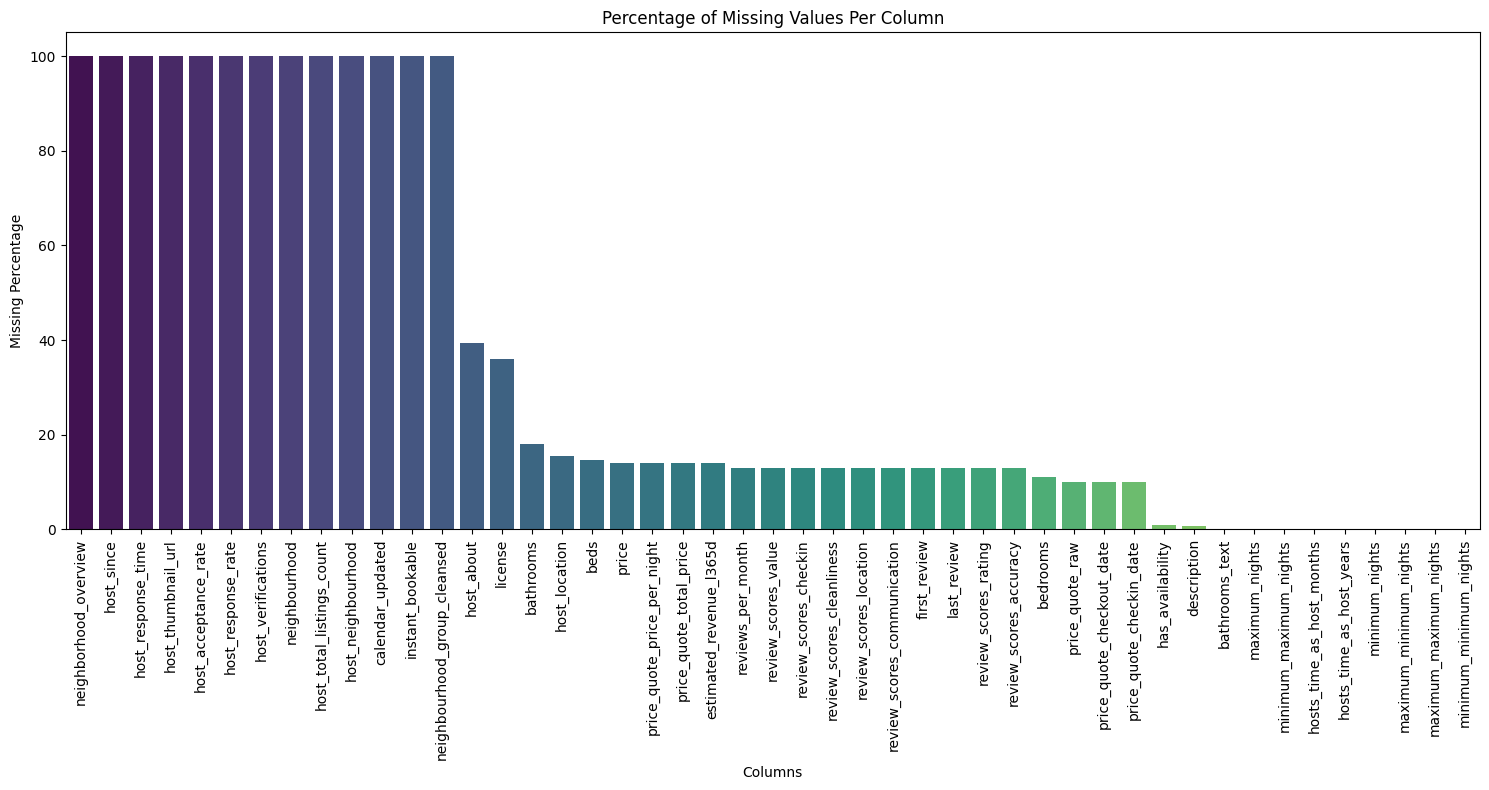

In [11]:
missing_data_barplot = missing_info[missing_info['Missing Percentage'] > 0].sort_values(by='Missing Percentage', ascending=False)

plt.figure(figsize=(15, 8))
sns.barplot(x=missing_data_barplot.index, y='Missing Percentage', data=missing_data_barplot, palette='viridis')
plt.xticks(rotation=90)
plt.title('Percentage of Missing Values Per Column')
plt.xlabel('Columns')
plt.ylabel('Missing Percentage')
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. The top 3 columns with the most missing values, all at 100%, are neighborhood_overview, host_since, and host_response_time. There are many more columns with 100% missing values as well, but the three just mentioned are the top three from the dataset and from what is displayed in the bar chart.
2. Columns like price, bedrooms, bathrooms, beds, and even one like review_scores are likely to create business issues if left with missing values, these columns are important for pricing models, search filters, and overall listing quality assessment.
3. I think columns with 100% missing values, such as neighborhood_overview, host_since, and host_response_time can be safely ignored or dropped since the information they contain is not that important.

## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [12]:
columns_to_drop = [
   'neighborhood_overview',
    'host_since',
    'host_response_time',
    'calendar_updated'
    ]

df = df.drop(columns=columns_to_drop)

print("Columns dropped successfully. Displaying the first few rows to confirm:")
df.head()

Columns dropped successfully. Displaying the first few rows to confirm:


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,360,https://www.airbnb.com/rooms/360,20260630053644,2026-06-30,city scrape,Denver’s Peaceful Oasis for Travel Nurses & No...,Enjoy the famous Colorado weather and unplug i...,https://a0.muscache.com/pictures/monet/Select-...,666,https://www.airbnb.com/users/show/666,...,4.99,4.98,4.90,2017-BFN-0002177,NaN,1,1,0,0,1.94
1,364,https://www.airbnb.com/rooms/364,20260630053644,2026-07-02,previous scrape,Lodo / RiNo LOFT via airport train,"Modern 1,000 square foot loft in the heart of ...",https://a0.muscache.com/pictures/11766413/a2c5...,783,https://www.airbnb.com/users/show/783,...,4.96,4.65,4.71,NaN,NaN,1,1,0,0,0.42
2,592,https://www.airbnb.com/rooms/592,20260630053644,2026-06-30,city scrape,private,This room is in the basement. It does not hav...,https://a0.muscache.com/pictures/ba522ff9-84c9...,933,https://www.airbnb.com/users/show/933,...,4.96,4.84,4.88,2021-BFN-0000578,NaN,1,0,1,0,1.05
3,686,https://www.airbnb.com/rooms/686,20260630053644,2026-06-30,city scrape,Alexandra's Queen Bed Room Long-term Rental Only,Thanks for visiting my Queen Bed Room for LONG...,https://a0.muscache.com/pictures/108112/e6d5d3...,990,https://www.airbnb.com/users/show/990,...,4.91,4.87,4.82,NaN,NaN,1,0,1,0,1.16
4,1940,https://www.airbnb.com/rooms/1940,20260630053644,2026-06-30,city scrape,"Baker Studio Pet-friendly, Walkable, Patio",Private studio retreat in a charming historic ...,https://a0.muscache.com/pictures/miso/Hosting-...,2150,https://www.airbnb.com/users/show/2150,...,4.99,4.90,4.90,2018-BFN-0002596,NaN,2,2,0,0,2.42


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. The columns I decided to drop were neighborhood_overview, host_since, host_response_time, and calendar_updated.
2. These columns were not useful from a business perspective because they all had 100% missing values. This means none of the data was useful since it was all missing, and you wouldn't be able to do any analysis, modeling, or make any informing business decisions using these columns.
3. If these columns were left in they would just add uneccesary data and complexity to the dataset. Even though they wouldn't directly cause errors, they would add more costs for processing and storing too.

## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [19]:
# 1. Fill missing values in 'host_about' with 'Unknown'
df['host_about'] = df['host_about'].fillna('Unknown')

# 2. Clean and convert 'price' column to numeric (float)
# First, remove '$' and ',' characters, then convert to float.
# Errors='coerce' will turn any values that cannot be converted into NaN.
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# 3. Fill missing values in 'price' with the median
median_price = df['price'].median()
df['price'] = df['price'].fillna(median_price)

print("Missing values for 'host_about' and 'price' have been filled.")
print("'price' column has been converted to numeric (float) and missing values imputed with the median.")
print("\nUpdated DataFrame Info:")
df.info(show_counts=True)

Missing values for 'host_about' and 'price' have been filled.
'price' column has been converted to numeric (float) and missing values imputed with the median.

Updated DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4939 entries, 0 to 4938
Data columns (total 86 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            4939 non-null   int64  
 1   listing_url                                   4939 non-null   object 
 2   scrape_id                                     4939 non-null   int64  
 3   last_scraped                                  4939 non-null   object 
 4   source                                        4939 non-null   object 
 5   name                                          4939 non-null   object 
 6   description                                   4904 non-null   object 
 7   picture_url                  

### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. The two columns I chose to clean were host_about, and price.

2. For the host_about column, I chose to use a strategy where I replaced all missing values with "unknown." This made sense because the absence of information could be fixed by putting unknown, rathr than putting in descritive statistics like mean, median, or mode. As for the second column, I chose to replace missing values with the median. This made sense because the price would have been more sensitive to the mean, but the median worked perfectly and made sense in this scenario.

3. Whenever you change missing data, there can always be risks. In my case, putting unknown could make the host_about column much less meaningful and not as helpful when trying to use that column to predict certain outcomes. It also could make the data less accurate. As for the price column, putting the median in could be risky becuase some of the values that were missing could've been important outliers, and many of them could be the mean, mode, or other statistics that would make the dataset more accurate.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [21]:
# 1. Identify 'first_review' as a column with the wrong data type
# It is currently an object type, but should be a datetime object.

# 2. Clean and convert 'first_review' into a usable format (datetime)
df['first_review'] = pd.to_datetime(df['first_review'], errors='coerce')

print("The 'first_review' column has been converted to datetime.")

# 3. Check your work by summarizing the cleaned column
print("\nUpdated DataFrame Info for 'first_review':")
df['first_review'].info()

print("\nDescriptive statistics for 'first_review':")
print(df['first_review'].describe())

The 'first_review' column has been converted to datetime.

Updated DataFrame Info for 'first_review':
<class 'pandas.core.series.Series'>
RangeIndex: 4939 entries, 0 to 4938
Series name: first_review
Non-Null Count  Dtype         
--------------  -----         
4301 non-null   datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 38.7 KB

Descriptive statistics for 'first_review':
count                             4301
mean     2022-07-27 16:28:00.725412608
min                2008-08-28 00:00:00
25%                2021-01-01 00:00:00
50%                2023-03-24 00:00:00
75%                2025-01-01 00:00:00
max                2026-06-28 00:00:00
Name: first_review, dtype: object


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. The column I chose to fix was first_review.

2. The cleaning step I applied was changing the Dtype from an object to datatime object, which fits the column more apropriately.

3. This helps prepare the data for future use by making the data type more consistent and accurate to the values in the column. The column deals with time, and instead of object, it is now datatime object which makes more sense for the column. It will make it easier to analyze in the future as well.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [22]:
# 1. Check for and remove exact duplicate rows
initial_row_count = df.shape[0]
df.drop_duplicates(inplace=True)
duplicates_removed_exact = initial_row_count - df.shape[0]

print(f"Removed {duplicates_removed_exact} exact duplicate rows.")

# 2. Check for and remove duplicate 'id' values (if 'id' is supposed to be unique)
# Keep the first occurrence of each unique 'id'
initial_row_count_after_exact_dedup = df.shape[0]
df.drop_duplicates(subset=['id'], keep='first', inplace=True)
duplicates_removed_id = initial_row_count_after_exact_dedup - df.shape[0]

print(f"Removed {duplicates_removed_id} rows with duplicate IDs (keeping the first occurrence).")

print(f"\nTotal rows after removing duplicates: {df.shape[0]}")

Removed 0 exact duplicate rows.
Removed 0 rows with duplicate IDs (keeping the first occurrence).

Total rows after removing duplicates: 4939


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. In the dataset I found for Denver AirBnB properties, I did not find any duplicates. With the code I used, it removed 0 exact duplicate rows and 0 rows with duplicate IDs.  

2. I did not have to decide what to drop or keep because my dataset didn't contain any rows that fit the criteria to be dropped, both from exact rows or rows with identical IDs.

3. Duplicates are risky for Airbnb teams because it can create flaws in the learning models created for analyzing the data, and it can also lead to poor user experience. They can make the data lesss accurate and even potentially skew the data in a very significant way if they arent dealt with.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [24]:
df.to_csv("cleaned_airbnb_data_6.csv", index=False)

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. I believe the hardest section for me in this lab was deciding which columns to delete entirely from the dataset. It was challenging because there were so many to choose from, and many of them were the same when it came to the usefulness of that column in the dataset. It wasn't much of a coding thing for me, but rather, application of class concepts and what was important to keep.
2. I think it was necessary to drop the columns I did because they contained 100% missing values, and didn't really serve any purpose from staying in the dataset. If anything, they would cause more of a mess and more hasstle from trying to navigate more columns.
3. A business team might benefit from a cleaned datset because the analysis they perform on the dataset will be more accurate. Having dropped columns that didn't fit the data set would help make things quicker and easier for the team to work with.
4. If I had more time, I would try and clean the dataset some more. I think there are a few more columns that could be dropped and potentially some more Dtypes that could be converted into a more fitting type.
5. This related to my customized learning outcomes because it helps me understand the impact of working with clean vs dirty datsets. Especially within the finance industry, its important that the data we deal with is clean and in the correct format so our analysis can be as accurate as possible.  


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [25]:
!jupyter nbconvert --to html "carpenter_henry_assignment_06_data_cleaning.ipynb"

[NbConvertApp] Converting notebook carpenter_henry_assignment_06_data_cleaning.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 699402 bytes to carpenter_henry_assignment_06_data_cleaning.html
